<a href="https://colab.research.google.com/github/deep25/DI-Bootcamp-Stage1/blob/main/Week4_Pokemon_challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
!unzip -o "/content/drive/MyDrive/Pokemon Data Analysis Tutorial.zip"

Archive:  /content/drive/MyDrive/Pokemon Data Analysis Tutorial.zip
  inflating: Pokemon Data Analysis Tutorial/combats.csv  
  inflating: Pokemon Data Analysis Tutorial/pokemon.csv  
  inflating: Pokemon Data Analysis Tutorial/tests.csv  


In [16]:
import pandas as pd
pokemon_data = pd.read_csv('Pokemon Data Analysis Tutorial/combats.csv')
poke_tests = pd.read_csv('Pokemon Data Analysis Tutorial/tests.csv')
pokemon_data_pokemon = pd.read_csv('Pokemon Data Analysis Tutorial/pokemon.csv')
display(pokemon_data.head())
display(poke_tests.head())
display(pokemon_data_pokemon.head())
pokemon_data.info()

,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151


,First_pokemon,Second_pokemon
0,129,117
1,660,211
2,706,115
3,195,618
4,27,656


,#,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False
3,4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False
4,5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   First_pokemon   50000 non-null  int64
 1   Second_pokemon  50000 non-null  int64
 2   Winner          50000 non-null  int64
dtypes: int64(3)
memory usage: 1.1 MB


In [17]:
import pandas as pd
import numpy as np

# Correcting the merge keys according to the dataset structure
merge_data = pd.merge(pokemon_data, pokemon_data_pokemon, left_on='First_pokemon', right_on='#')
merge_data = merge_data.rename(columns={'Type 1': 'first_pokemon_type_1', 'Type 2': 'first_pokemon_type_2'})

merge_data = pd.merge(merge_data, pokemon_data_pokemon, left_on='Second_pokemon', right_on='#')
merge_data = merge_data.rename(columns={'Type 1': 'second_pokemon_type_1', 'Type 2': 'second_pokemon_type_2'})

merge_data = pd.merge(merge_data, pokemon_data_pokemon, left_on='Winner', right_on='#')
merge_data = merge_data.rename(columns={'Type 1': 'winner_type_1', 'Type 2': 'winner_type_2'})

merge_data = merge_data.drop(['First_pokemon', 'Second_pokemon', 'Winner'], axis=1)
merge_data.head()

,#_x,Name_x,first_pokemon_type_1,first_pokemon_type_2,HP_x,Attack_x,Defense_x,Sp. Atk_x,Sp. Def_x,Speed_x,...,winner_type_1,winner_type_2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,266,Larvitar,Rock,Ground,50,64,50,45,50,41,...,Grass,Dark,70,70,40,60,40,60,3,False
1,702,Virizion,Grass,Fighting,91,90,72,90,129,108,...,Rock,Fighting,91,129,90,72,90,108,5,True
2,191,Togetic,Fairy,Flying,55,40,85,80,105,40,...,Psychic,NaN,75,75,75,125,95,40,5,False
3,237,Slugma,Fire,NaN,40,40,40,70,40,20,...,Dragon,NaN,77,120,90,60,90,48,5,False
4,151,Omastar,Rock,Water,70,60,125,115,70,55,...,Rock,Water,70,60,125,115,70,55,1,False


In [18]:
import pandas as pd
import numpy as np

# Correctly fill the missing name 'Primeape' for Pokemon #62 in pokemon_data_pokemon first
pokemon_data_pokemon.loc[pokemon_data_pokemon['#'] == 62, 'Name'] = 'Primeape'

# Also fill the missing Name values in our merged DataFrame
# The columns containing the pokemon names are 'Name_x' (first pokemon), 'Name_y' (second pokemon), and 'Name' (winner pokemon)
if '#_x' in merge_data.columns:
    merge_data.loc[merge_data['#_x'] == 62, 'Name_x'] = merge_data.loc[merge_data['#_x'] == 62, 'Name_x'].fillna('Primeape')
if '#_y' in merge_data.columns:
    merge_data.loc[merge_data['#_y'] == 62, 'Name_y'] = merge_data.loc[merge_data['#_y'] == 62, 'Name_y'].fillna('Primeape')
if '#' in merge_data.columns:
    merge_data.loc[merge_data['#'] == 62, 'Name'] = merge_data.loc[merge_data['#'] == 62, 'Name'].fillna('Primeape')

# Verify if Pokemon #62 is successfully updated
print("Number of remaining missing names for Pokemon #62:")
print("Name_x missing for ID 62:", merge_data[merge_data['#_x'] == 62]['Name_x'].isnull().sum())
print("Name_y missing for ID 62:", merge_data[merge_data['#_y'] == 62]['Name_y'].isnull().sum())
print("Winner Name missing for ID 62:", merge_data[merge_data['#'] == 62]['Name'].isnull().sum())

# Check the remaining overall missing values in the entire dataset
print("\nTotal remaining missing values across all Pokemon in these columns:")
missing_value = merge_data.isnull().sum()
print(missing_value[['Name_x', 'Name_y', 'Name']])

Number of remaining missing names for Pokemon #62:
Name_x missing for ID 62: 0
Name_y missing for ID 62: 0
Winner Name missing for ID 62: 0

Total remaining missing values across all Pokemon in these columns:
Name_x    56
Name_y    52
Name      85
dtype: int64


In [20]:
import pandas as pd
import numpy as np

# Define the Type 2 columns in the merged dataset
type_2_columns = ['first_pokemon_type_2', 'second_pokemon_type_2', 'winner_type_2']

# Fill NaN values with 'None' for these specific columns
for col in type_2_columns:
    if col in merge_data.columns:
        merge_data[col] = merge_data[col].fillna('None')

# Print the remaining missing values in these columns to verify
print("Remaining missing values in Type 2 columns:")
print(merge_data[type_2_columns].isnull().sum())

# Display the first few rows to confirm
display(merge_data[type_2_columns].head())

Remaining missing values in Type 2 columns:
first_pokemon_type_2     0
second_pokemon_type_2    0
winner_type_2            0
dtype: int64


,first_pokemon_type_2,second_pokemon_type_2,winner_type_2
0,Ground,Dark,Dark
1,Fighting,Fighting,Fighting
2,Flying,None,None
3,None,None,None
4,Water,Rock,Water


In [27]:
import pandas as pd
import numpy as np

# 1. Count total battles for each Pokemon
first_counts = pokemon_data['First_pokemon'].value_counts()
second_counts = pokemon_data['Second_pokemon'].value_counts()
total_battles = first_counts.add(second_counts, fill_value=0)

# 2. Count total wins for each Pokemon
wins_counts = pokemon_data['Winner'].value_counts()

# 3. Combine into a new DataFrame
win_stats = pd.DataFrame({
    'Battles': total_battles,
    'Wins': wins_counts
}).fillna(0)

# 4. Calculate win percentage
win_stats['Win_Percentage'] = (win_stats['Wins'] / win_stats['Battles']) * 100

# 5. Bring in Pokemon names from pokemon_data_pokemon for readability
pokemon_names = pokemon_data_pokemon.set_index('#')['Name']
win_stats = win_stats.join(pokemon_names)

# Sort and display the top 10 Pokemon with the highest win rate
win_stats = win_stats[['Name', 'Battles', 'Wins', 'Win_Percentage']].sort_values(by='Win_Percentage', ascending=False)
display(win_stats.head(10))

,Name,Battles,Wins,Win_Percentage
155,Mega Aerodactyl,129,127.0,98.449612
513,Weavile,119,116.0,97.478992
704,Tornadus Therian Forme,125,121.0,96.800000
20,Mega Beedrill,119,115.0,96.638655
154,Aerodactyl,141,136.0,96.453901
477,Mega Lopunny,129,124.0,96.124031
727,Greninja,127,122.0,96.062992
717,Meloetta Pirouette Forme,123,118.0,95.934959
165,Mega Mewtwo Y,125,119.0,95.200000
350,Mega Sharpedo,120,114.0,95.000000


In [32]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Create a DataFrame combining Pokemon base stats with their win percentage
# We set '#' as index to align with win_stats
pokemon_base = pokemon_data_pokemon.set_index('#')
correlation_df = win_stats.join(pokemon_base[['HP', 'Attack']], how='inner')

# Calculate Pearson correlation coefficient and p-value for HP vs Win_Percentage
corr_hp, p_hp = stats.pearsonr(correlation_df['HP'], correlation_df['Win_Percentage'])
print(f"HP & Win Percentage Correlation Coefficient: {corr_hp:.4f} (p-value: {p_hp:.4e})")

# Calculate Pearson correlation coefficient and p-value for Attack vs Win_Percentage
corr_attack, p_attack = stats.pearsonr(correlation_df['Attack'], correlation_df['Win_Percentage'])
print(f"Attack & Win Percentage Correlation Coefficient: {corr_attack:.4f} (p-value: {p_attack:.4e})")

HP & Win Percentage Correlation Coefficient: 0.2616 (p-value: 9.8308e-14)
Attack & Win Percentage Correlation Coefficient: 0.5028 (p-value: 1.8136e-51)


<Figure size 1200x1200 with 0 Axes>

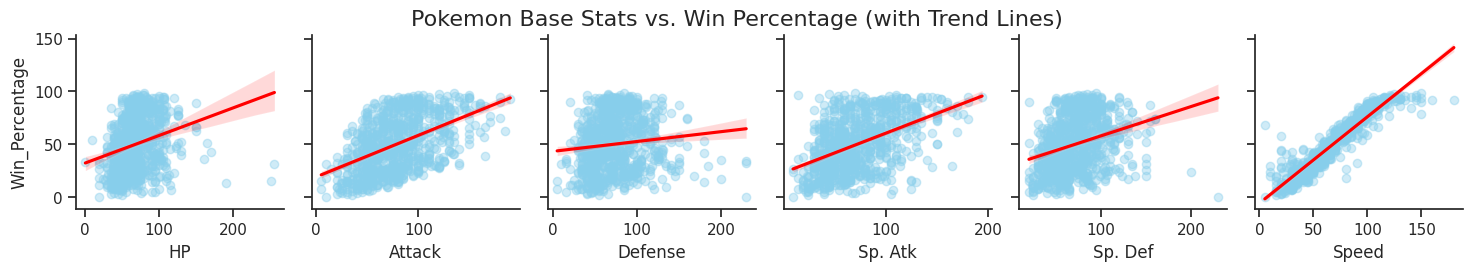

In [36]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare the dataset combining win statistics and all base stats
pokemon_base_all = pokemon_data_pokemon.set_index('#')
stats_columns = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']

# Join our win_stats with the base stats columns
plot_df = win_stats[['Win_Percentage']].join(pokemon_base_all[stats_columns], how='inner')

# 2. Plot a PairPlot to visualize relations between each Stat and Win Percentage
plt.figure(figsize=(12, 12))
sns.set_theme(style="ticks")

# We'll plot Win_Percentage on the y-axis against each of the stats on the x-axis
g = sns.pairplot(
    plot_df,
    y_vars=['Win_Percentage'],
    x_vars=stats_columns,
    kind='reg',  # Adds a linear regression line to see the trend
    plot_kws={'line_kws': {'color': 'red'}, 'scatter_kws': {'alpha': 0.4, 'color': 'skyblue'}}
)

g.fig.suptitle('Pokemon Base Stats vs. Win Percentage (with Trend Lines)', y=1.05, fontsize=16)
plt.show()


In [38]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#Top 10 pokemon by win percent and stats
pokemon_base_all = pokemon_data_pokemon.set_index('#')
stats_columns = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']
plot_df = win_stats[['Win_Percentage']].join(pokemon_base_all[stats_columns], how='inner')
plot_df = plot_df.sort_values(by='Win_Percentage', ascending=False)
top_10_pokemon = plot_df.head(10)
print(top_10_pokemon)




     Win_Percentage   HP  Attack  Defense  Sp. Atk  Sp. Def  Speed
155       98.449612   80     135       85       70       95    150
513       97.478992   70     120       65       45       85    125
704       96.800000   79     100       80      110       90    121
20        96.638655   65     150       40       15       80    145
154       96.453901   80     105       65       60       75    130
477       96.124031   65     136       94       54       96    135
727       96.062992   72      95       67      103       71    122
717       95.934959  100     128       90       77       77    128
165       95.200000  106     150       70      194      120    140
350       95.000000   70     140       70      110       65    105


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# We will predict 'Win_Percentage' using the 'Attack' stat.
# We use the correlation_df which aligns individual pokemon stats with their win percentage.
X_simple = correlation_df['Attack'].values.reshape(-1, 1)
y = correlation_df['Win_Percentage'].values

# Split the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X_simple, y, test_size=0.2, random_state=42)

# Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)
y_pred_simple = model.predict(X_test)

#random forest model
from sklearn.ensemble import RandomForestRegressor
random_forest_model = RandomForestRegressor(n_estimators=100, random_state=42)
random_forest_model.fit(X_train, y_train)
y_pred_random_forest = random_forest_model.predict(X_test)
random_forest_r2 = r2_score(y_test, y_pred_random_forest)
random_forest_mae = mean_absolute_error(y_test, y_pred_random_forest)
random_forest_rmse = np.sqrt(mean_squared_error(y_test, y_pred_random_forest))
print(f"Random Forest R2 Score: {random_forest_r2:.4f}")
print(f"Random Forest Mean Absolute Error: {random_forest_mae:.4f}")
print(f"Random Forest root mean square error: {random_forest_rmse: .4f}")


# Evaluate and print the results
print(f"Model R2 Score: {r2_score(y_test, y_pred_simple):.4f}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred_simple):.4f}")

#XGBoost model
from xgboost import XGBRegressor
xgb_model = XGBRegressor(n_estimators=100, random_state=4)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
xgb_r2 = r2_score(y_test, X_test)
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
print(f"XGBoost R2 Score: {xgb_r2:.4f}")
print(f"XGBoost Mean Absolute Error: {xgb_mae:.4f}")
print(f"XGBoost root mean square error: {xgb_rmse}")

Random Forest R2 Score: 0.1404
Random Forest Mean Absolute Error: 19.2314
Random Forest root mean square error:  23.1525
Model R2 Score: 0.1596
Mean Absolute Error: 19.1631
XGBoost R2 Score: -1.7263
XGBoost Mean Absolute Error: 19.5625
XGBoost root mean square error: 23.61872923208066


,Model,MAE
0,Linear Regression,19.163143
1,Random Forest,19.231352
2,XGBoost,19.562535


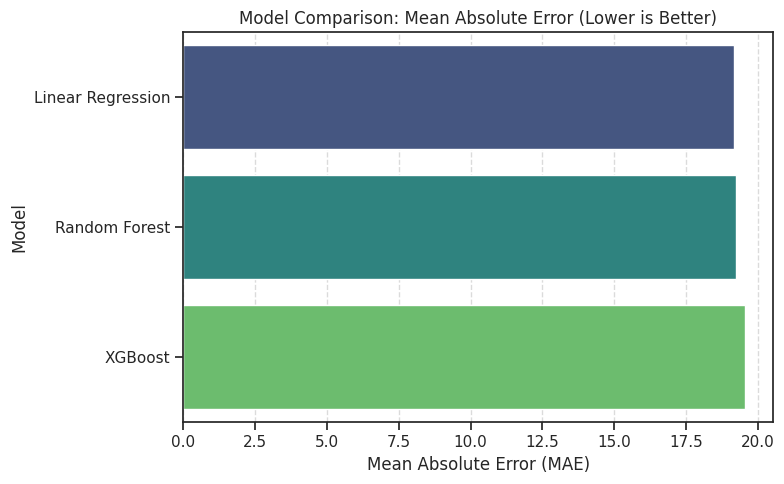

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate Simple Linear Regression MAE
linear_mae = mean_absolute_error(y_test, y_pred_simple)

# Gather MAE metrics
mae_comparison = {
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'MAE': [linear_mae, random_forest_mae, xgb_mae]
}

# Create a DataFrame for easy visualization and display
mae_df = pd.DataFrame(mae_comparison).sort_values(by='MAE')
display(mae_df)

# Plot the comparison
plt.figure(figsize=(8, 5))
sns.barplot(x='MAE', y='Model', data=mae_df, palette='viridis', hue='Model', legend=False)
plt.title('Model Comparison: Mean Absolute Error (Lower is Better)')
plt.xlabel('Mean Absolute Error (MAE)')
plt.ylabel('Model')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()